# 06 · Análisis no supervisado: K-Means y PCA
**Unidad IV · Fase CRISP-DM:** 4. Modelado y 5. Evaluación

**Objetivo:** descubrir **grupos naturales (perfiles morfológicos)** de abulones usando solo sus medidas físicas, **sin decirle al modelo la edad ni el sexo**.

🧠 **No supervisado** = el modelo **no recibe la respuesta correcta**. En la regresión y la clasificación le dábamos la edad para que aprendiera; aquí solo le damos las medidas y él solo encuentra qué abulones se parecen entre sí.

| Técnica | Qué hace | Analogía |
|---|---|---|
| **K-Means** | Forma *k* grupos poniendo juntos a los abulones con medidas parecidas | Acomodar ropa en montones por talla sin ver la etiqueta |
| **PCA** | Resume las 7 medidas en 2 o 3 "súper variables" (componentes) que conservan casi toda la información | Describir a una persona con "tamaño general" en vez de 7 medidas |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RUTA_PROC = Path("..") / "data" / "processed"
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_MOD = Path("..") / "modelos"
SEMILLA = 42

df = pd.read_csv(RUTA_PROC / "abalone_limpio.csv")
MEDIDAS = ["Length", "Diameter", "Height", "Whole_weight",
           "Shucked_weight", "Viscera_weight", "Shell_weight"]
print("Registros:", len(df))

Registros: 4169


## 1. Preparar los datos: escalar
K-Means mide **distancias** entre abulones. Si una variable tiene números más grandes, "pesaría" más. Con **StandardScaler** todas quedan en la misma escala (media 0, desviación 1).

⚠️ Se usan **solo las 7 medidas físicas**: ni `Rings` ni `Sex`, para que los grupos salgan únicamente de la forma y el peso.

In [2]:
escalador = StandardScaler()
X = escalador.fit_transform(df[MEDIDAS])
print("Forma de X:", X.shape)
print("Media de cada columna (≈0):", X.mean(axis=0).round(2))

Forma de X: (4169, 7)
Media de cada columna (≈0): [-0.  0.  0.  0.  0.  0. -0.]


## 2. ¿Cuántos grupos (k)? Método del codo y coeficiente de silueta
- **Inercia (codo):** qué tan compactos son los grupos. Siempre baja al aumentar *k*; se busca el punto donde **deja de bajar mucho** (el "codo").
- **Silueta:** de −1 a 1. Mide si cada abulón está **más cerca de su grupo que de los otros**. Mayor es mejor; más de 0.4 se considera una estructura razonable.

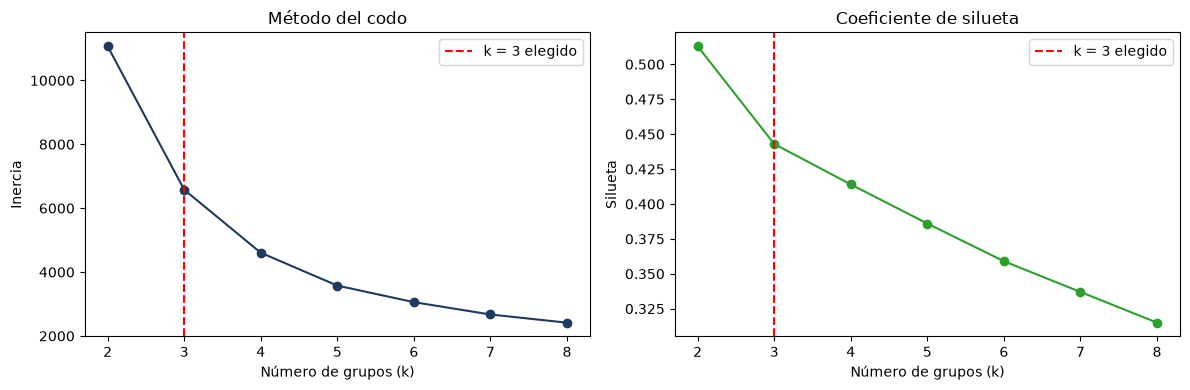

,k,Inercia,Silueta
0,2,11072.0,0.513
1,3,6579.0,0.443
2,4,4605.0,0.414
3,5,3577.0,0.386
4,6,3058.0,0.359
5,7,2672.0,0.337
6,8,2416.0,0.315


In [3]:
resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    resultados.append({"k": k, "Inercia": round(km.inertia_, 0),
                       "Silueta": round(silhouette_score(X, km.labels_), 3)})
tabla_k = pd.DataFrame(resultados)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(tabla_k["k"], tabla_k["Inercia"], "o-", color="#1F3A5F")
a1.axvline(3, color="red", linestyle="--", label="k = 3 elegido")
a1.set_title("Método del codo"); a1.set_xlabel("Número de grupos (k)"); a1.set_ylabel("Inercia"); a1.legend()
a2.plot(tabla_k["k"], tabla_k["Silueta"], "o-", color="#2CA02C")
a2.axvline(3, color="red", linestyle="--", label="k = 3 elegido")
a2.set_title("Coeficiente de silueta"); a2.set_xlabel("Número de grupos (k)"); a2.set_ylabel("Silueta"); a2.legend()
plt.tight_layout(); plt.savefig(RUTA_FIG / "14_codo_silueta.png", dpi=130); plt.show()
tabla_k

**Decisión: k = 3.**
- En el **codo**, la inercia baja mucho de 2 a 3 grupos y después baja cada vez menos.
- La **silueta** de k = 3 (≈ 0.44) es buena. La de k = 2 es un poco mayor, pero 2 grupos solo separan "chicos" de "grandes" y dan poca información.
- **3 grupos son fáciles de interpretar** para un productor: pequeños, medianos y grandes.

## 3. Entrenar K-Means con k = 3

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit(X)
df["Cluster"] = kmeans.labels_

# K-Means numera los grupos al azar (0, 1, 2). Les damos un nombre según su tamaño promedio.
orden = df.groupby("Cluster")["Length_mm"].mean().sort_values().index
nombres = dict(zip(orden, ["Pequeño", "Mediano", "Grande"]))
df["Perfil"] = df["Cluster"].map(nombres)
print(df["Perfil"].value_counts().reindex(["Pequeño", "Mediano", "Grande"]))
print("\nSilueta final:", round(silhouette_score(X, kmeans.labels_), 3))

Perfil
Pequeño    1139
Mediano    1759
Grande     1271
Name: count, dtype: int64

Silueta final: 0.443


## 4. Interpretar los perfiles
Se comparan las medidas **reales** (mm y g) promedio de cada grupo, y luego se revisa qué edad y sexo tienen sus integrantes **(información que el modelo nunca vio)**.

In [5]:
ORDEN = ["Pequeño", "Mediano", "Grande"]
perfil = df.groupby("Perfil").agg(
    Abulones=("ID_Abulon", "count"),
    Longitud_mm=("Length_mm", "mean"),
    Diametro_mm=("Diameter_mm", "mean"),
    Altura_mm=("Height_mm", "mean"),
    Peso_total_g=("Whole_weight_g", "mean"),
    Peso_concha_g=("Shell_weight_g", "mean"),
    Rings_prom=("Rings", "mean"),
    Edad_prom_anios=("Edad_anios", "mean"),
).reindex(ORDEN).round(1)
perfil

,Abulones,Longitud_mm,Diametro_mm,Altura_mm,Peso_total_g,Peso_concha_g,Rings_prom,Edad_prom_anios
Perfil,,,,,,,,
Pequeño,1139,73.5,55.7,18.4,52.7,16.0,7.3,8.8
Mediano,1759,107.4,83.7,28.3,154.5,45.4,10.4,11.9
Grande,1271,129.5,102.0,35.7,283.1,79.5,11.7,13.2


In [6]:
print("Composición por SEXO (% de cada perfil):")
print((pd.crosstab(df["Perfil"], df["Sexo"], normalize="index") * 100).round(1).reindex(ORDEN))
print("\nComposición por GRUPO DE EDAD (% de cada perfil):")
print((pd.crosstab(df["Perfil"], df["Grupo_Edad"], normalize="index") * 100).round(1)
      .reindex(ORDEN)[["Joven", "Adulto", "Maduro"]])

Composición por SEXO (% de cada perfil):
Sexo     Hembra  Infante  Macho
Perfil                         
Pequeño    10.6     70.9   18.5
Mediano    33.0     27.9   39.1
Grande     47.5      3.0   49.5

Composición por GRUPO DE EDAD (% de cada perfil):
Grupo_Edad  Joven  Adulto  Maduro
Perfil                           
Pequeño      77.1    15.5     7.4
Mediano      26.8    37.9    35.4
Grande        4.0    37.7    58.3


**Interpretación:**
| Perfil | Cómo es | ¿Quiénes son? |
|---|---|---|
| **Pequeño** | ≈ 74 mm de largo y 53 g | Mayoría **infantes** (≈ 71%) y **jóvenes** (≈ 77%); en promedio 7.3 anillos |
| **Mediano** | ≈ 107 mm y 155 g | Mezcla de sexos y edades; en promedio 10.4 anillos |
| **Grande** | ≈ 130 mm y 283 g | Casi solo **machos y hembras** (≈ 97%), sobre todo **maduros** (≈ 58%); 11.7 anillos |

💡 **Hallazgo:** sin conocer la edad, el modelo separó a los abulones en etapas que **coinciden con su madurez**: casi no hay infantes en el grupo grande. Pero el grupo **Mediano** mezcla edades: muchos abulones dejan de crecer al llegar a adultos, por lo que **el tamaño solo no basta** para saber la edad exacta. Esto explica por qué la regresión tiene un error de ≈ 1.5 anillos.

## 5. PCA: reducir 7 medidas a 2 componentes
**PCA** combina las variables originales en nuevas variables llamadas **componentes principales** (PC1, PC2…), ordenadas de la que más información conserva a la que menos.

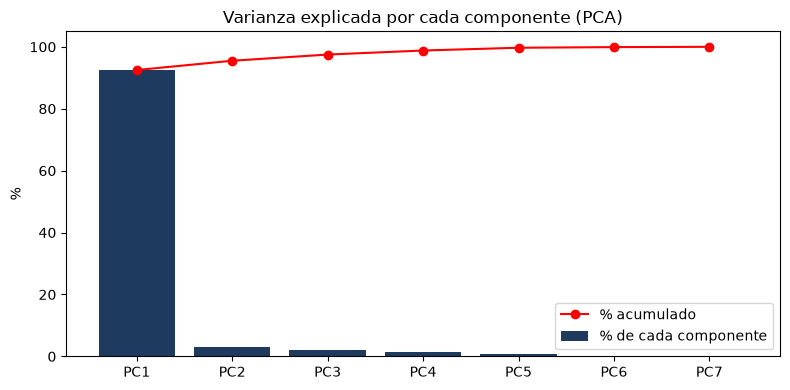

,Componente,% varianza,% acumulado
0,PC1,92.5,92.5
1,PC2,3.0,95.5
2,PC3,2.0,97.5
3,PC4,1.3,98.8
4,PC5,0.9,99.7
5,PC6,0.2,99.9
6,PC7,0.1,100.0


In [7]:
pca = PCA().fit(X)
varianza = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(MEDIDAS))],
    "% varianza": (pca.explained_variance_ratio_ * 100).round(1),
    "% acumulado": (pca.explained_variance_ratio_.cumsum() * 100).round(1),
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(varianza["Componente"], varianza["% varianza"], color="#1F3A5F", label="% de cada componente")
ax.plot(varianza["Componente"], varianza["% acumulado"], "o-", color="red", label="% acumulado")
ax.set_title("Varianza explicada por cada componente (PCA)"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.savefig(RUTA_FIG / "15_pca_varianza.png", dpi=130); plt.show()
varianza

In [8]:
# ¿Qué significa PC1? Su peso (carga) en cada medida
cargas = pd.DataFrame(pca.components_[:2].T, index=MEDIDAS, columns=["PC1", "PC2"]).round(3)
cargas

,PC1,PC2
Length,0.380,0.311
Diameter,0.381,0.346
Height,0.367,0.553
Whole_weight,0.387,-0.317
Shucked_weight,0.375,-0.494
Viscera_weight,0.378,-0.365
Shell_weight,0.376,-0.019


**Interpretación:**
- **PC1 conserva ≈ 92.5% de toda la información** de las 7 medidas. Todas sus cargas son positivas y parecidas → PC1 es básicamente el **"tamaño general"** del abulón.
- Con **PC1 + PC2 se conserva ≈ 95.5%**. Es decir, 7 columnas se pueden resumir en **2 casi sin perder información**, porque las medidas están muy correlacionadas (lo vimos en el EDA: > 0.9).
- PC2 tiene cargas opuestas en la altura frente a los pesos → representa pequeñas diferencias de **forma** (abulones más altos o más "planos" para su peso).

## 6. Visualizar los grupos con PCA

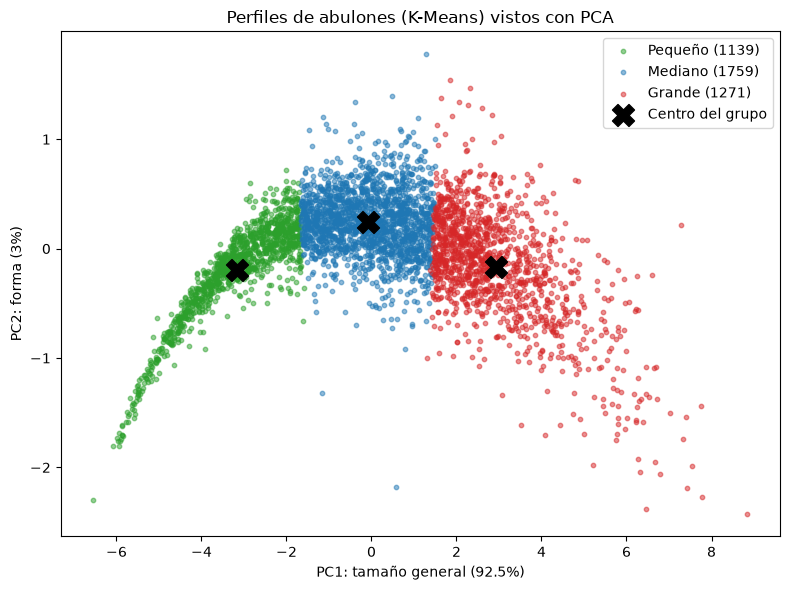

In [9]:
pca2 = PCA(n_components=2).fit(X)
comp = pca2.transform(X)
df["PC1"], df["PC2"] = comp[:, 0].round(4), comp[:, 1].round(4)

colores = {"Pequeño": "#2CA02C", "Mediano": "#1F77B4", "Grande": "#D62728"}
fig, ax = plt.subplots(figsize=(8, 6))
for p in ORDEN:
    g = df[df["Perfil"] == p]
    ax.scatter(g["PC1"], g["PC2"], s=10, alpha=0.5, color=colores[p], label=f"{p} ({len(g)})")
centros = pca2.transform(kmeans.cluster_centers_)
ax.scatter(centros[:, 0], centros[:, 1], s=250, c="black", marker="X", label="Centro del grupo")
ax.set_title("Perfiles de abulones (K-Means) vistos con PCA")
ax.set_xlabel("PC1: tamaño general (92.5%)"); ax.set_ylabel("PC2: forma (3%)")
ax.legend()
plt.tight_layout(); plt.savefig(RUTA_FIG / "16_clusters_pca.png", dpi=130); plt.show()

**Interpretación:** los tres grupos se ordenan de izquierda a derecha a lo largo de **PC1 (tamaño)**: pequeños, medianos y grandes. Las X negras son los **centros** de cada grupo. Los límites entre grupos se tocan porque el crecimiento es continuo: no hay saltos bruscos entre un abulón pequeño y uno mediano.

## 7. ¿Los grupos coinciden con la edad?

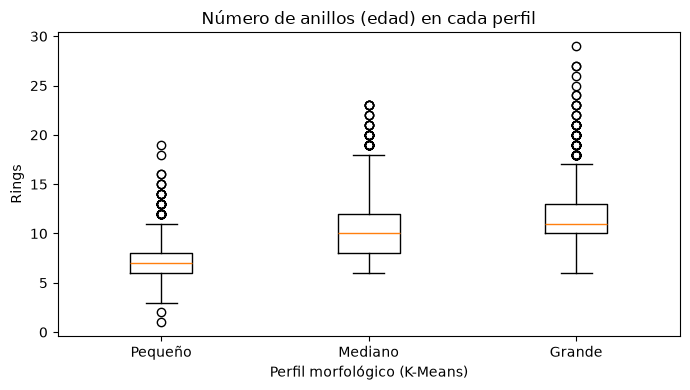

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
datos = [df.loc[df["Perfil"] == p, "Rings"] for p in ORDEN]
ax.boxplot(datos)
ax.set_xticks([1, 2, 3], ORDEN)
ax.set_title("Número de anillos (edad) en cada perfil")
ax.set_xlabel("Perfil morfológico (K-Means)"); ax.set_ylabel("Rings")
plt.tight_layout(); plt.savefig(RUTA_FIG / "17_rings_por_perfil.png", dpi=130); plt.show()

**Interpretación:** la edad **sube** de un perfil al siguiente, pero las cajas se **traslapan**: hay abulones medianos tan viejos como algunos grandes. Confirma que el tamaño indica la etapa de crecimiento, pero no la edad exacta.

## 8. Guardar resultados
Se guardan para cargarlos en SQL Server y mostrarlos en el **dashboard de Power BI**.

In [11]:
salida = df[["ID_Abulon", "Cluster", "Perfil", "PC1", "PC2"]]
salida.to_csv(RUTA_PROC / "abalone_clusters.csv", index=False, encoding="utf-8", lineterminator="\n")
tabla_k.to_csv(Path("..") / "docs" / "metricas_clustering.csv", index=False, encoding="utf-8-sig")
perfil.to_csv(Path("..") / "docs" / "perfiles_clusters.csv", encoding="utf-8-sig")
joblib.dump({"escalador": escalador, "kmeans": kmeans, "pca": pca2, "nombres": nombres},
            RUTA_MOD / "kmeans_pca.joblib", compress=3)
print("Guardado: data/processed/abalone_clusters.csv, docs/metricas_clustering.csv,",
      "docs/perfiles_clusters.csv y modelos/kmeans_pca.joblib")

Guardado: data/processed/abalone_clusters.csv, docs/metricas_clustering.csv, docs/perfiles_clusters.csv y modelos/kmeans_pca.joblib


## 9. Conclusiones
1. **K-Means con k = 3** encontró tres perfiles morfológicos: **Pequeño, Mediano y Grande**, con silueta ≈ 0.44 (estructura razonable).
2. Sin conocer la edad, los perfiles **coinciden con la madurez**: el perfil Pequeño es mayoritariamente de infantes jóvenes y el Grande de adultos maduros.
3. **PCA** demostró que las 7 medidas se resumen en **un solo factor de "tamaño general" (92.5%)**; con 2 componentes se conserva el 95.5% de la información.
4. El traslape de edades entre perfiles confirma la **limitación** detectada en la regresión: después de cierta edad el abulón casi deja de crecer.
5. **Utilidad práctica:** una granja podría clasificar rápido a sus abulones por perfil (solo midiéndolos) para decidir cuáles ya están listos para cosecha.